# Sentiment Analysis of Song Lyrics

Questions:
1. Which sentiments and emotions dominate each genre?
2. Do they change over the years?
3. Does sentiment relate to popularity (views)?
4. Do the sentiment tools agree with each other?

## Setup

In [1]:
from pathlib import Path

import numpy as np
import polars as pl
import matplotlib.pyplot as plt

SEED = 80085
data_dir = Path("data")

## Loading the Data

All labelled songs are used: no model is trained here, so the train/validation split does not matter. The input is `lyrics_sentiment` from `preprocessing_unified.ipynb`: lightly cleaned lyrics that keep punctuation, casing and stopwords, which the lexicon tools use as cues. Songs over the 512-token limit of the transformer are split into two parts.

In [2]:
songs = pl.read_parquet(data_dir / "data-transformers" / "transformers_train.parquet",
                        columns=["id", "title", "artist", "year", "views", "tag", "lyrics_sentiment"])
print(f"{songs.height:,} songs")
songs["lyrics_sentiment"].list.len().value_counts().rename({"lyrics_sentiment": "parts"})

134,526 songs


parts,count
u32,u32
2,35291
1,99235


### Year and Views

`year` and `views` are needed for questions 2 and 3, so their quality is checked first.

shape: (9, 3)
┌────────────┬────────────┬──────────────┐
│ statistic  ┆ year       ┆ views        │
│ ---        ┆ ---        ┆ ---          │
│ str        ┆ f64        ┆ f64          │
╞════════════╪════════════╪══════════════╡
│ count      ┆ 134526.0   ┆ 134526.0     │
│ null_count ┆ 0.0        ┆ 0.0          │
│ mean       ┆ 2009.46536 ┆ 3423.001078  │
│ std        ┆ 46.353734  ┆ 41992.639889 │
│ min        ┆ 1.0        ┆ 0.0          │
│ 25%        ┆ 2008.0     ┆ 22.0         │
│ 50%        ┆ 2015.0     ┆ 90.0         │
│ 75%        ┆ 2019.0     ┆ 474.0        │
│ max        ┆ 2024.0     ┆ 3.604497e6   │
└────────────┴────────────┴──────────────┘


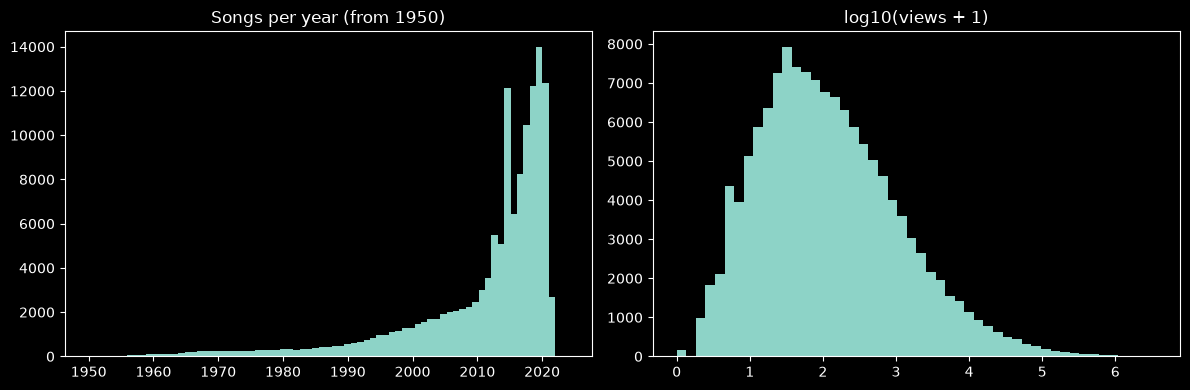

In [3]:
print(songs.select("year", "views").describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(songs.filter(pl.col("year") >= 1950)["year"], bins=75)
axes[0].set_title("Songs per year (from 1950)")
axes[1].hist(np.log10(songs["views"] + 1), bins=50)
axes[1].set_title("log10(views + 1)")
plt.tight_layout()
plt.show()

**Result.** `year` contains impossible values (minimum 1, some songs from the 1800s), and most songs are from 2010–2022, so the trends over the years are only analysed for years with enough songs. `views` is extremely skewed (median 90, maximum 3.6 million), so it is analysed on a log scale and with rank correlation.

## VADER

VADER (Hutto & Gilbert, 2014) was built for short texts such as tweets, so every **line** of a song is scored on its own, and a song is described by:
- `vader_compound`: the mean compound score of its lines,
- `vader_pos` / `vader_neg`: the share of positive (≥ 0.05) and negative (≤ −0.05) lines, the thresholds Hutto & Gilbert recommend for a single VADER score.

Two details of the line split:
- **A repeated chorus counts every time it is sung.** This is intended: repetition is how a song stresses its message.
- **Long lines are cut.** 823 songs have no line breaks at all (the lyrics were saved as one block), so the whole song would be scored as one text. A lyric line has 6 words in the median and fewer than 24 in 99% of the cases, so every "line" of more than 20 words is cut into pieces of 20 words.

The two parts of long songs are joined again, since VADER has no length limit.

In [4]:
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer

nltk.download("vader_lexicon", quiet=True)
vader = SentimentIntensityAnalyzer()

songs = songs.with_columns(text=pl.col("lyrics_sentiment").list.join("\n\n"))

MAX_WORDS = 20


def song_lines(text):
    """The non-empty lines of a song, lines over MAX_WORDS words cut into pieces of MAX_WORDS words."""
    for line in text.split("\n"):
        words = line.split()
        for start in range(0, len(words), MAX_WORDS):
            yield " ".join(words[start:start + MAX_WORDS])


assert list(song_lines("a b\n\n  \nc")) == ["a b", "c"]
assert len(list(song_lines(" ".join(["word"] * 45)))) == 3


def vader_song(text):
    scores = np.array([vader.polarity_scores(line)["compound"] for line in song_lines(text)])
    return {"vader_compound": scores.mean(), "vader_pos": (scores >= 0.05).mean(), "vader_neg": (scores <= -0.05).mean()}

### Why per Line?

A check on 2,000 random songs: the compound score of the whole song against the mean of its lines.

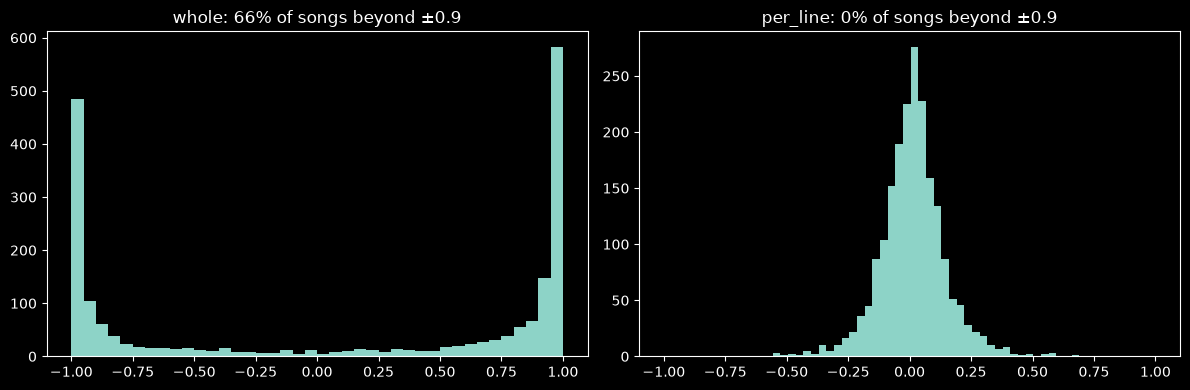

title,artist,tag,whole,per_line
str,str,str,f64,f64
"""Someone Like You""","""KIDZ BOP Kids""","""pop""",0.9622,0.047055
"""Mad World""","""Scott Bradlee's Postmodern Juk…","""pop""",-0.988,-0.117213


In [5]:
def compare(df):
    return df.select(
        "title", "artist", "tag",
        whole=pl.col("text").map_elements(lambda t: vader.polarity_scores(t)["compound"], return_dtype=pl.Float64),
        per_line=pl.col("text").map_elements(lambda t: vader_song(t)["vader_compound"], return_dtype=pl.Float64))


demo = compare(songs.sample(2000, seed=SEED))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
for ax, col in zip(axes, ["whole", "per_line"]):
    ax.hist(demo[col], bins=40)
    ax.set_title(f"{col}: {(demo[col].abs() > 0.9).mean():.0%} of songs beyond ±0.9")
plt.tight_layout()
plt.show()

# two well-known sad songs, chosen by id because several different songs share these titles:
# Adele's "Someone Like You" (KIDZ BOP cover), Tears for Fears' "Mad World" (Postmodern Jukebox cover)
SAD_SONG_IDS = [2259575, 1486438]
compare(songs.filter(pl.col("id").is_in(SAD_SONG_IDS)))

**Result.** Scored as a whole, 66% of the songs land beyond ±0.9: VADER adds up the scores of all words and squashes the sum into [−1, 1], so a long text is almost always "extremely" positive or negative. Adele's *Someone Like You* (here the KIDZ BOP cover) even gets +0.96, because words like *love* and *wish* are repeated many times, while *Mad World* gets −0.99. Per line, the scores spread around 0 (most lines are neutral): *Someone Like You* comes out neutral (+0.05) and *Mad World* slightly negative (−0.12). The per-line scores are therefore used from here on.

### Scoring All Songs

Scoring all songs takes a few minutes, so the scores are saved to `data/data-sentiment/vader.parquet` and loaded from there afterwards.

In [6]:
sent_dir = data_dir / "data-sentiment"
vader_path = sent_dir / "vader.parquet"

if vader_path.exists():
    vader_scores = pl.read_parquet(vader_path)
else:
    sent_dir.mkdir(exist_ok=True)
    vader_scores = pl.DataFrame([vader_song(t) for t in songs["text"]]).insert_column(0, songs["id"])
    vader_scores.write_parquet(vader_path)

songs = songs.join(vader_scores, on="id")
songs.select("vader_compound", "vader_pos", "vader_neg").describe()

statistic,vader_compound,vader_pos,vader_neg
str,f64,f64,f64
"""count""",134526.0,134526.0,134526.0
"""null_count""",0.0,0.0,0.0
"""mean""",0.012617,0.253653,0.224059
"""std""",0.126969,0.150987,0.152899
"""min""",-0.9186,0.0,0.0
"""25%""",-0.057466,0.146667,0.109589
"""50%""",0.0115,0.232558,0.2
"""75%""",0.080842,0.333333,0.314286
"""max""",0.96686,1.0,1.0


## TextBlob

TextBlob gives two scores per text:
- `polarity` from −1 (negative) to +1 (positive),
- `subjectivity` from 0 (factual) to 1 (opinionated, emotional).

Unlike VADER, it **averages** the scores of the words it knows instead of adding them up, so a long text does not saturate at ±1 and the whole song is scored at once.

In [7]:
from textblob import TextBlob

blob_path = sent_dir / "textblob.parquet"

if blob_path.exists():
    blob_scores = pl.read_parquet(blob_path)
else:
    sentiments = [TextBlob(t).sentiment for t in songs["text"]]
    blob_scores = pl.DataFrame({"id": songs["id"],
                                "blob_polarity": [s.polarity for s in sentiments],
                                "blob_subjectivity": [s.subjectivity for s in sentiments]})
    blob_scores.write_parquet(blob_path)

songs = songs.join(blob_scores, on="id")
songs.select("blob_polarity", "blob_subjectivity").describe()

statistic,blob_polarity,blob_subjectivity
str,f64,f64
"""count""",134526.0,134526.0
"""null_count""",0.0,0.0
"""mean""",0.061665,0.506043
"""std""",0.179439,0.134802
"""min""",-1.0,0.0
"""25%""",-0.045139,0.431508
"""50%""",0.05361,0.508519
"""75%""",0.16553,0.584314
"""max""",1.0,1.0


**Result.** TextBlob's polarity is centred slightly above 0 (median 0.05), like VADER's, and no song saturates except a few very short ones. Subjectivity is around 0.5 for most songs: lyrics mix descriptions with feelings. The two sad songs show a weakness of TextBlob: *Mad World* is very subjective (0.77) but almost neutral (+0.02), and *Someone Like You* is neutral as well (+0.08). TextBlob does not recognise their sadness, a point taken up again in Q4.

## Emotions

VADER and TextBlob only measure polarity (positive or negative). To see *which* emotions dominate a genre, a pretrained transformer, `j-hartmann/emotion-english-distilroberta-base` (Hartmann, 2022), predicts the probabilities of 7 emotions: anger, disgust, fear, joy, neutral, sadness and surprise. It is a DistilRoBERTa model fine-tuned on six emotion datasets (tweets, Reddit, dialogues and self-reports); the accuracy of this family of transformer models is evaluated by Hartmann et al. (2023). Neither source tests the model on song lyrics, so its scores here are not validated (see the limitations). No training happens here, the model is only used for prediction.

The model reads at most 512 tokens, which is why `lyrics_sentiment` splits long songs into two parts. Each part is scored, and a song with two parts gets the mean of both.

The results are saved in chunks of 10,000 parts, so an interrupted run continues where it stopped, and the final scores are saved to `data/data-sentiment/emotions.parquet`.

*References:*
- Hartmann, J. (2022). *Emotion English DistilRoBERTa-base* [Model]. Hugging Face. https://huggingface.co/j-hartmann/emotion-english-distilroberta-base
- Hartmann, J., Heitmann, M., Siebert, C., & Schamp, C. (2023). More than a feeling: Accuracy and application of sentiment analysis. *International Journal of Research in Marketing, 40*(1), 75–87.

In [8]:
import torch
from tqdm.auto import tqdm
from transformers import pipeline

EMOTIONS = ["anger", "disgust", "fear", "joy", "neutral", "sadness", "surprise"]
emotion_path = sent_dir / "emotions.parquet"
chunk_dir = sent_dir / "emotion_chunks"
CHUNK = 10_000

if emotion_path.exists():
    emotion_scores = pl.read_parquet(emotion_path)
else:
    device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
    classifier = pipeline("text-classification", model="j-hartmann/emotion-english-distilroberta-base",
                          top_k=None, truncation=True, device=device)

    # one row per part, sorted by length so a batch needs little padding;
    # id and text break the ties, so a rerun gets exactly the same chunks
    parts = (songs.select("id", part="lyrics_sentiment").explode("part")
             .sort(pl.col("part").str.len_chars(), "id", "part"))

    chunk_dir.mkdir(exist_ok=True)
    for start in tqdm(range(0, parts.height, CHUNK)):
        path = chunk_dir / f"{start:06d}.parquet"
        if path.exists():
            continue
        chunk = parts.slice(start, CHUNK)
        predictions = classifier(chunk["part"].to_list(), batch_size=32)
        probs = pl.DataFrame([{p["label"]: p["score"] for p in pred} for pred in predictions]).select(EMOTIONS)
        pl.concat([chunk.select("id"), probs], how="horizontal").write_parquet(path)

    emotion_scores = (pl.read_parquet(chunk_dir / "*.parquet").group_by("id").mean()
                      .rename({e: f"emo_{e}" for e in EMOTIONS}))
    emotion_scores.write_parquet(emotion_path)

assert emotion_scores.height == songs.height, "some songs have no emotion scores: delete emotion_chunks/ and rerun"
songs = songs.join(emotion_scores, on="id")
songs.select(pl.col("^emo_.*$").mean())

W1125 18:49:48.538000 60908 .venv/lib/python3.13/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


emo_anger,emo_disgust,emo_fear,emo_joy,emo_neutral,emo_sadness,emo_surprise
f64,f64,f64,f64,f64,f64,f64
0.198749,0.074307,0.233927,0.052698,0.155283,0.218489,0.066547


## Q1: Sentiment and Emotions per Genre

### Polarity

The distribution of the three polarity scores per genre. Genres are ordered by their median VADER score (this order is kept in all following plots and tables), outliers are hidden (with 134k songs they would cover the boxes), and the table gives the mean of every score.

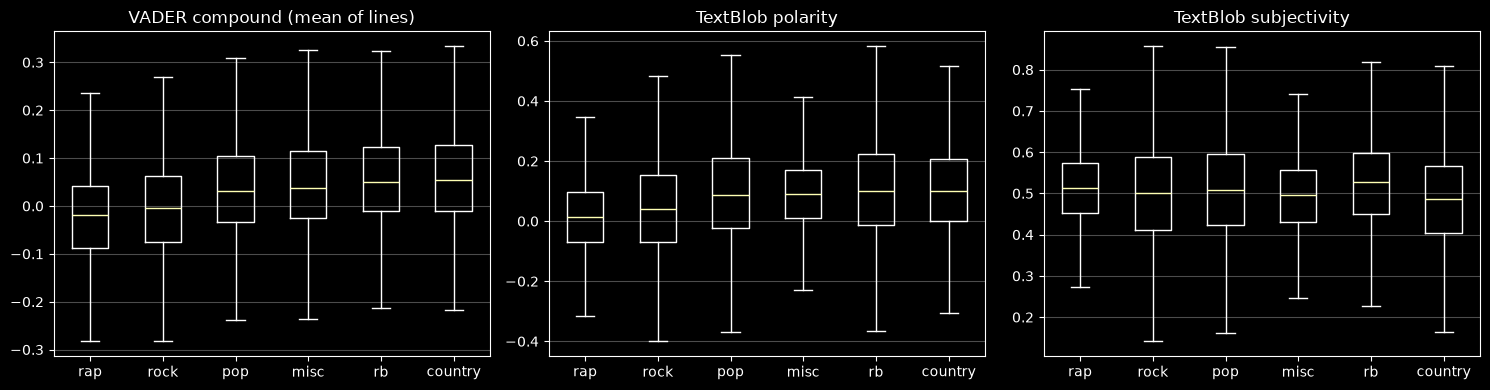

tag,vader_compound,blob_polarity,blob_subjectivity,vader_pos,vader_neg
str,f64,f64,f64,f64,f64
"""rap""",-0.026,0.015,0.512,0.25,0.277
"""rock""",-0.007,0.042,0.498,0.223,0.235
"""pop""",0.037,0.092,0.506,0.259,0.191
"""misc""",0.045,0.092,0.493,0.298,0.215
"""rb""",0.059,0.106,0.522,0.292,0.18
"""country""",0.063,0.109,0.487,0.294,0.18


In [9]:
GENRES = songs.group_by("tag").agg(pl.col("vader_compound").median()).sort("vader_compound")["tag"].to_list()
GENRE_ORDER = pl.col("tag").replace_strict(GENRES, list(range(len(GENRES))))   # sort key: genres in GENRES order
POLARITY = {"vader_compound": "VADER compound (mean of lines)",
            "blob_polarity": "TextBlob polarity",
            "blob_subjectivity": "TextBlob subjectivity"}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (col, title) in zip(axes, POLARITY.items()):
    ax.boxplot([songs.filter(pl.col("tag") == g)[col] for g in GENRES], tick_labels=GENRES, showfliers=False)
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

songs.group_by("tag").agg(pl.col(*POLARITY, "vader_pos", "vader_neg").mean().round(3)).sort(GENRE_ORDER)

### Emotions

The mean probability of every emotion per genre, in the same genre order. Darker cells mean the emotion is more present in the genre.

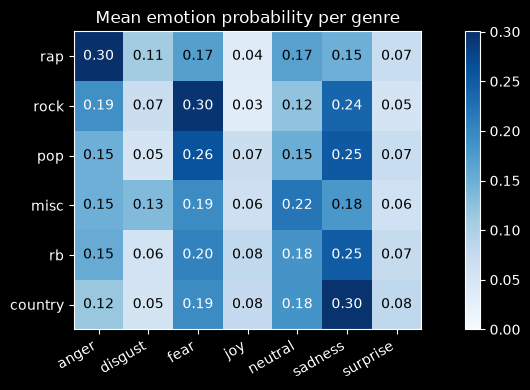

In [10]:
EMO_COLS = [f"emo_{e}" for e in EMOTIONS]
emotion_means = songs.group_by("tag").agg(pl.col(EMO_COLS).mean()).sort(GENRE_ORDER)
matrix = emotion_means.select(EMO_COLS).to_numpy()

fig, ax = plt.subplots(figsize=(9, 4))
image = ax.imshow(matrix, cmap="Blues", vmin=0)
ax.set_xticks(range(len(EMOTIONS)), EMOTIONS, rotation=30, ha="right")
ax.set_yticks(range(len(GENRES)), GENRES)
for i, j in np.ndindex(matrix.shape):
    ax.text(j, i, f"{matrix[i, j]:.2f}", ha="center", va="center",
            color="white" if matrix[i, j] > 0.6 * matrix.max() else "black")
ax.set_title("Mean emotion probability per genre")
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

### Are the Differences Real?

The Kruskal-Wallis test checks whether a score differs between the genres. It compares ranks instead of means, so it does not assume normal distributions (the scores are skewed and bounded). With 134k songs even tiny differences are "significant", so the effect size η²_H = (H − k + 1) / (n − k) (Tomczak & Tomczak, 2014) shows how large they are: about 0.01 is small, 0.06 medium and 0.14 large.

*Reference:* Tomczak, M., & Tomczak, E. (2014). The need to report effect size estimates revisited. An overview of some recommended measures of effect size. *Trends in Sport Sciences, 1*(21), 19–25.

In [11]:
from scipy.stats import kruskal

k, n = len(GENRES), songs.height
tests = []
for col in [*POLARITY, *EMO_COLS]:
    h, p = kruskal(*[songs.filter(pl.col("tag") == g)[col] for g in GENRES])
    tests.append({"score": col, "H": round(h), "p_value": p, "eta2_H": round((h - k + 1) / (n - k), 3)})

pl.DataFrame(tests).sort("eta2_H", descending=True)

score,H,p_value,eta2_H
str,i64,f64,f64
"""emo_anger""",15222,0.0,0.113
"""emo_disgust""",14168,0.0,0.105
"""vader_compound""",8621,0.0,0.064
"""emo_joy""",6603,0.0,0.049
"""blob_polarity""",6099,0.0,0.045
"""emo_surprise""",5658,0.0,0.042
"""emo_neutral""",4119,0.0,0.031
"""emo_sadness""",3416,0.0,0.025
"""emo_fear""",2248,0.0,0.017


**Result.**
- **Polarity:** rap and rock are the most negative genres (mean VADER −0.03 and −0.01; in rap 28% of the lines are negative), R&B and country the most positive (+0.06), with pop and misc in between (+0.04). The effect is medium for VADER (η²_H = 0.06) and small for TextBlob (0.05). Subjectivity hardly differs between genres (0.003): all genres are about equally emotional, they differ in *which* emotion.
- **Emotions:** anger separates the genres best (η²_H = 0.11): rap is clearly the angriest genre (0.30 against at most 0.19 elsewhere), and with misc also the most disgusted. Country is the saddest genre (0.30), rock the most fearful (0.30), and misc the most neutral.
- **Joy** is low in every genre (at most 0.08), although both lexicons rate lyrics slightly positive on average. Either many love songs are about longing and loss, or the emotion model, trained on social-media text, misreads lyrics; this is a limitation of the analysis.
- All p-values are practically 0, but the effect sizes are at most medium: the genres differ on average, while the songs *within* a genre vary much more than the genre means. This fits the difficulty of predicting the genre from the lyrics alone.

## Q2: Changes over the Years

Most songs are from 2010 onwards and rap hardly exists before 1990, so single years are too noisy. The songs are grouped into 5-year periods (1965 = 1965–1969) from 1960 on, and a genre is only shown for the periods with at least 100 songs. The plots follow VADER polarity and the three emotions that dominate the genres (anger, fear, sadness).

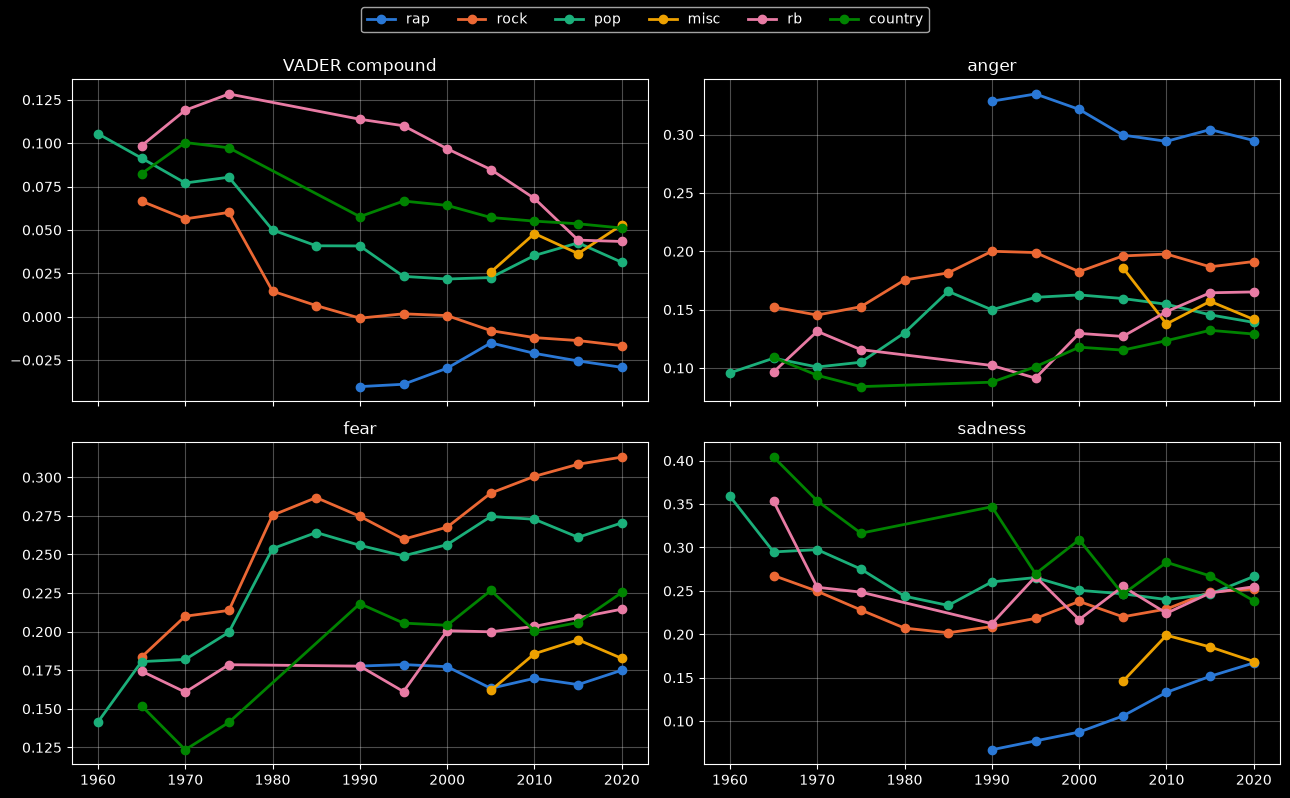

In [12]:
MIN_SONGS = 100
TREND = {"vader_compound": "VADER compound", "emo_anger": "anger", "emo_fear": "fear", "emo_sadness": "sadness"}
# colour-blind-safe categorical palette, one fixed colour per genre
GENRE_COLORS = dict(zip(GENRES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]))

since_1960 = songs.filter(pl.col("year") >= 1960)
by_period = (since_1960.with_columns(period=pl.col("year") // 5 * 5)
             .group_by("tag", "period")
             .agg(pl.len().alias("songs"), pl.col(*TREND).mean())
             .filter(pl.col("songs") >= MIN_SONGS)
             .sort("period"))

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
for ax, (col, title) in zip(axes.flat, TREND.items()):
    for genre in GENRES:
        line = by_period.filter(pl.col("tag") == genre)
        ax.plot(line["period"], line[col], marker="o", lw=2, color=GENRE_COLORS[genre], label=genre)
    ax.set_title(title)
    ax.grid(alpha=0.3)
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper center", ncols=len(GENRES))
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

### Strength of the Trends

The plots show the direction, the Spearman rank correlation between `year` and each score (per genre, songs from 1960 on) shows how strong a trend is: 0 means no trend, ±0.1 a weak and ±0.3 a moderate one (Cohen, 1988).

*Reference:* Cohen, J. (1988). *Statistical power analysis for the behavioral sciences* (2nd ed.). Lawrence Erlbaum Associates.

In [13]:
from scipy.stats import spearmanr

trends = []
for genre in GENRES:
    genre_songs = since_1960.filter(pl.col("tag") == genre)
    trends.append({"genre": genre, "songs": genre_songs.height,
                   **{col: round(spearmanr(genre_songs["year"], genre_songs[col]).statistic, 3) for col in TREND}})

pl.DataFrame(trends)

genre,songs,vader_compound,emo_anger,emo_fear,emo_sadness
str,i64,f64,f64,f64,f64
"""rap""",38495,-0.02,-0.027,0.008,0.099
"""rock""",25238,-0.086,-0.012,0.057,0.034
"""pop""",55110,-0.013,0.015,0.057,0.026
"""misc""",4769,-0.004,-0.009,0.004,-0.015
"""rb""",6139,-0.157,0.064,0.047,0.031
"""country""",3330,-0.095,0.173,0.163,-0.105


**Result.**
- **Lyrics became less positive.** In every genre with old songs the mean VADER score falls from the 1960s/70s to today: pop from 0.10 to 0.03, R&B from 0.13 to 0.04 (the strongest trend, ρ = −0.16), rock from 0.07 to below 0.
- **Rock and pop became more fearful** (rock 0.18 → 0.31, pop 0.14 → 0.27), **rap became sadder**: its sadness more than doubles from 0.07 (early 1990s) to 0.17 (2020s), while its anger drops slightly (0.33 → 0.29).
- **Country** moves the other way: less sad (ρ = −0.11), more angry and fearful (ρ = 0.17 and 0.16).
- The correlations are weak (|ρ| ≤ 0.17): the change of the period means is clear, but small compared to the spread between songs of the same period.
- **Limitation:** older songs are probably a selection. A lyrics website likely holds mostly the old songs that are still known today, so the early periods may not be a random sample of their time. Lines also skip periods with fewer than 100 songs (e.g. R&B in the 1980s).

## Q3: Sentiment and Popularity

Two things distort a direct comparison of views:
- **Age.** Older songs had more time to collect views (Spearman ρ between `year` and `views`: −0.25). Only songs from 2015–2021 are used, the years with the most songs and a similar time online.
- **Genre.** Typical view counts differ per genre (median from 20 for misc to 153 for country), so the correlation is computed within every genre, and once over all genres together.

The Spearman correlation uses ranks, so the skew of `views` does not matter.

In [14]:
recent = songs.filter(pl.col("year").is_between(2015, 2021))
SCORES = ["vader_compound", "blob_polarity", *EMO_COLS]

popularity = []
for genre in ["all", *GENRES]:
    group = recent if genre == "all" else recent.filter(pl.col("tag") == genre)
    popularity.append({"genre": genre, "songs": group.height,
                       **{col: round(spearmanr(group["views"], group[col]).statistic, 3) for col in SCORES}})

pl.DataFrame(popularity)

genre,songs,vader_compound,blob_polarity,emo_anger,emo_disgust,emo_fear,emo_joy,emo_neutral,emo_sadness,emo_surprise
str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""all""",75850,0.032,0.027,0.032,0.088,0.034,0.052,0.059,-0.029,0.048
"""rap""",28284,-0.054,-0.018,0.098,0.195,0.016,0.025,0.048,-0.086,0.023
"""rock""",13046,0.1,0.071,-0.014,0.021,0.019,0.079,0.084,-0.003,0.089
"""pop""",26562,0.065,0.036,0.024,0.067,0.036,0.054,0.059,-0.019,0.043
"""misc""",2055,-0.101,-0.073,0.076,0.023,0.156,0.015,-0.064,0.083,0.094
"""rb""",4476,0.008,-0.003,0.047,0.134,0.088,0.022,0.064,-0.087,0.028
"""country""",1427,-0.002,-0.027,0.084,0.114,0.025,0.009,0.067,-0.021,0.035


### Sentiment along the Popularity Scale

A correlation only captures a steady rise or fall. To also see other shapes (e.g. only the most viewed songs being different), the songs of every genre are split into 10 groups by views (decile 1 = least viewed, 10 = most viewed), and the mean scores of each group are compared.

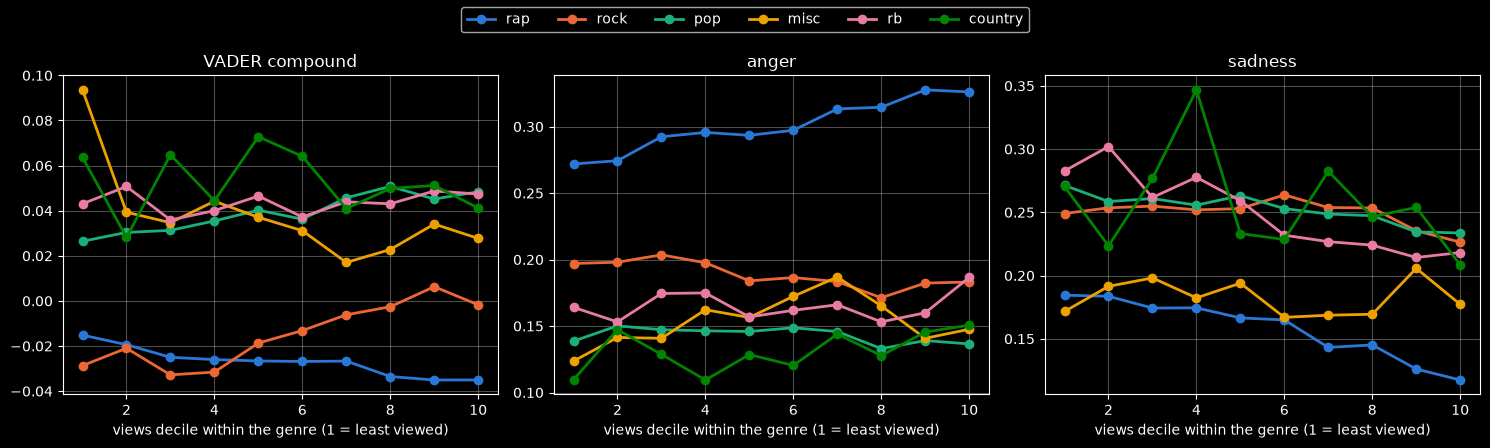

In [15]:
DECILE_SCORES = {"vader_compound": "VADER compound", "emo_anger": "anger", "emo_sadness": "sadness"}

# average rank: songs with the same views land in the same decile
by_decile = (recent.with_columns(decile=(pl.col("views").rank("average").over("tag") * 10 / pl.len().over("tag"))
                                 .ceil().cast(pl.Int8))
             .group_by("tag", "decile").agg(pl.col(*DECILE_SCORES).mean())
             .sort("decile"))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True)
for ax, (col, title) in zip(axes, DECILE_SCORES.items()):
    for genre in GENRES:
        line = by_decile.filter(pl.col("tag") == genre)
        ax.plot(line["decile"], line[col], marker="o", lw=2, color=GENRE_COLORS[genre], label=genre)
    ax.set_title(title)
    ax.set_xlabel("views decile within the genre (1 = least viewed)")
    ax.grid(alpha=0.3)
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncols=len(GENRES))
plt.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()

**Result.**
- **Sentiment hardly explains popularity.** All correlations are weak (|ρ| ≤ 0.2), within the genres as well as over all genres together.
- **Rap is the clearest case:** the more viewed a rap song, the angrier (0.27 → 0.33 from the least to the most viewed decile) and the less sad (0.18 → 0.12) it is. Disgust has the strongest correlation with views in the whole table (ρ = 0.20).
- **Rock and pop:** popular songs are slightly more positive and joyful (rock ρ = 0.10 for VADER, 0.08 for joy).
- Misc and country jump between deciles: with 2,055 and 1,427 songs, a decile only holds 140–200 songs.
- Popularity also depends on things the lyrics do not show (the artist, the music, promotion), so a weak relation is not surprising.

## Q4: Do the Tools Agree?

### Correlation between the Scores

The Spearman correlation between every pair of scores over all songs (blue: rise together, red: one rises while the other falls). The emotion probabilities sum to 1, so they are partly negatively correlated with each other by construction; the interesting part is how they relate to the lexicon scores.

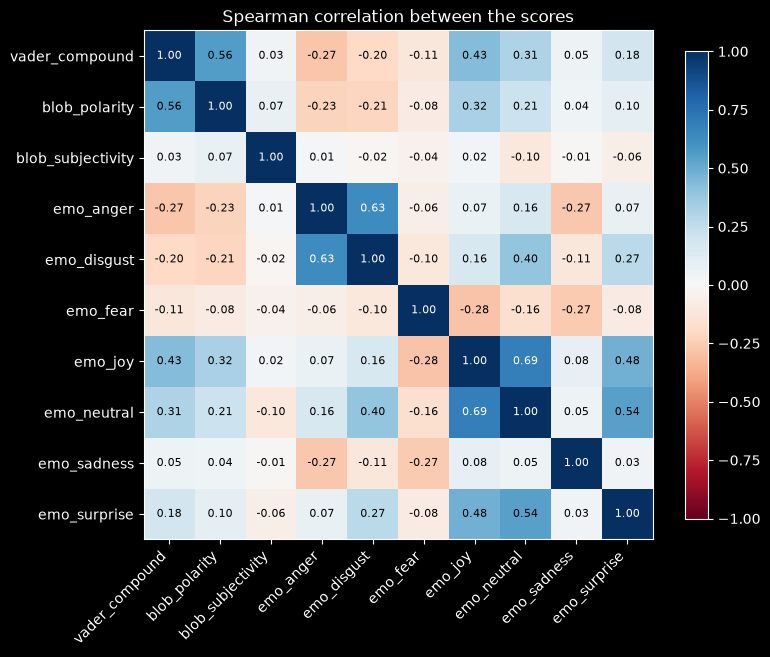

In [16]:
ALL_SCORES = [*POLARITY, *EMO_COLS]
# Spearman = Pearson correlation of the ranks
corr = songs.select(pl.col(ALL_SCORES).rank()).corr().to_numpy()

fig, ax = plt.subplots(figsize=(8, 7))
image = ax.imshow(corr, cmap="RdBu", vmin=-1, vmax=1)
ax.set_xticks(range(len(ALL_SCORES)), ALL_SCORES, rotation=45, ha="right")
ax.set_yticks(range(len(ALL_SCORES)), ALL_SCORES)
for i, j in np.ndindex(corr.shape):
    ax.text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center", fontsize=8,
            color="white" if abs(corr[i, j]) > 0.6 else "black")
ax.set_title("Spearman correlation between the scores")
fig.colorbar(image, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

### Agreement on the Label

A correlation says whether the scores move together, not whether the tools would give a song the same label. Each song is therefore labelled positive, negative or neutral by VADER and by TextBlob. Cohen's kappa corrects the share of agreeing labels for the agreement expected by chance (0 = chance, 1 = perfect; 0.21–0.40 counts as fair, 0.41–0.60 as moderate, following Landis & Koch, 1977).

The threshold of ±0.05 is our own choice: Hutto & Gilbert recommend it for a *single* VADER score, while `vader_compound` is a mean of lines (pulled towards 0), and TextBlob has no recommended threshold. The agreement is therefore checked for three thresholds.

*Reference:* Landis, J. R., & Koch, G. G. (1977). The measurement of observer agreement for categorical data. *Biometrics, 33*(1), 159–174.

In [17]:
from sklearn.metrics import cohen_kappa_score


def polarity_label(col, threshold=0.05):
    return (pl.when(pl.col(col) >= threshold).then(pl.lit("positive"))
            .when(pl.col(col) <= -threshold).then(pl.lit("negative"))
            .otherwise(pl.lit("neutral")))


for threshold in (0.025, 0.05, 0.1):
    labels = songs.select(vader=polarity_label("vader_compound", threshold),
                          textblob=polarity_label("blob_polarity", threshold))
    print(f"threshold ±{threshold}: same label {(labels['vader'] == labels['textblob']).mean():.1%}, "
          f"Cohen's kappa {cohen_kappa_score(labels['vader'], labels['textblob']):.2f}")

# rows: VADER, columns: TextBlob, share of all songs, threshold ±0.05
labels = songs.select(vader=polarity_label("vader_compound"), textblob=polarity_label("blob_polarity"))
order = ["negative", "neutral", "positive"]
(labels.group_by("vader", "textblob").len()
 .with_columns((pl.col("len") / songs.height).round(3))
 .pivot("textblob", index="vader", values="len")
 .select("vader", *order)
 .sort(pl.col("vader").replace_strict(order, [0, 1, 2])))

threshold ±0.025: same label 57.6%, Cohen's kappa 0.31
threshold ±0.05: same label 52.8%, Cohen's kappa 0.29
threshold ±0.1: same label 56.5%, Cohen's kappa 0.28


vader,negative,neutral,positive
str,f64,f64,f64
"""negative""",0.134,0.079,0.059
"""neutral""",0.081,0.122,0.178
"""positive""",0.025,0.05,0.273


**Result.**
- **VADER and TextBlob agree only moderately** (ρ = 0.56). They give the same label to 53% of the songs (Cohen's κ = 0.29, fair agreement), and κ stays between 0.28 and 0.31 for all three thresholds, so this does not depend on the threshold. They rarely contradict each other: only 8.4% of the songs are positive for one tool and negative for the other. Most disagreements are neutral against positive or negative, and TextBlob calls more songs positive (51% against 35% for VADER).
- **The lexicons and the emotion model agree on joy and anger** (VADER ρ = 0.43 with joy, −0.27 with anger), **but not on sadness and fear** (ρ = 0.05 and −0.11). A sad song is not scored negative by the lexicons, often because it is full of words like *love* and *miss* (see *Someone Like You* and *Mad World* above). This explains the puzzle of Q1: the lexicons rate the lyrics slightly positive while the emotion model finds little joy and much sadness. The two kinds of tools measure different things, which is why both are used.
- Subjectivity is unrelated to every other score (|ρ| ≤ 0.10).

## Limitations

### Are All Texts English Lyrics?

All three tools only understand English. English lyrics consist of about half stopwords (*I*, *you*, *the*, ...), so a text with a much lower share of English stopwords is either in another language or not a lyric at all.

In [18]:
from nltk.corpus import stopwords

nltk.download("stopwords", quiet=True)
english_stopwords = list(set(stopwords.words("english")))

stop_share = songs.select("tag", "text", share=pl.col("text").str.to_lowercase().str.extract_all(r"[a-z']+")
                                               .list.eval(pl.element().is_in(english_stopwords)).list.mean())
print(f"median stopword share: {stop_share['share'].median():.2f}, "
      f"texts below 0.2: {(stop_share['share'] < 0.2).sum()} of {stop_share.height:,}")

# the texts with the fewest English stopwords
for row in stop_share.sort("share").head(5).iter_rows(named=True):
    print(f"{row['share']:.2f} {row['tag']:8} {row['text'][:80]!r}")

stop_share.group_by("tag").agg(below_02=(pl.col("share") < 0.2).mean().round(3)).sort(GENRE_ORDER)

median stopword share: 0.50, texts below 0.2: 335 of 134,526
0.00 rock     'Stealing, raping, killing, lying\nGenocide, torture, race hate\nWar, murder, slaug'
0.00 rock     '*inaudible high-pitched voice*\n*inaudible high-pitched voice*\n\nInsane inflame\n\n*'
0.00 pop      'Grant Green - Guitar\nJohnny Acea - Piano\nWendell Marshall - Bass\nWillie Bobo - D'
0.00 pop      'Cannonball Adderley - alto saxophone\nDonald Byrd - trumpet\nJerome Richardson - t'
0.00 pop      'Yes whu, Yes whu, Yes whu, Yes whu, Yes whu, Yes whu, Yes whu, Yes whu, Yes whu,'


tag,below_02
str,f64
"""rap""",0.002
"""rock""",0.002
"""pop""",0.002
"""misc""",0.016
"""rb""",0.002
"""country""",0.0


**Result.** The median text is half stopwords, and only 335 texts (0.25%) fall below 0.2. The texts with the fewest stopwords are English as well: lyrics written as word lists, album credits or tables, not songs in another language. Such texts are most frequent in misc (1.6%), too few to change any result.

### Summary of the Limitations

- **No validation against human labels.** None of the scores was checked against labelled lyrics. The emotion model was trained on social-media text, so the low joy in every genre may partly be an error of the model rather than a property of the lyrics.
- **The tools measure different things.** The lexicons react to positive words and miss sadness (ρ = 0.05 between VADER and sadness), so a sad love song can look positive. Polarity results alone would misrepresent the emotional tone of a genre.
- **Design choices.** VADER scores are means of lines, a repeated chorus counts every time, lines over 20 words are cut, and the ±0.05 threshold is our own choice. The agreement between the tools hardly depends on the threshold (κ 0.28–0.31), the other choices were not varied.
- **Old songs are probably survivors.** A lyrics website likely holds mostly the old songs that are still known today, so the trends over the years may compare a selection of old songs with almost all recent ones.
- **Views are a weak measure of popularity.** They come from one website, depend on the age of a song (only 2015–2021 was used) and on things the lyrics do not show, such as the artist.
- **Genre labels are coarse.** Misc mixes very different texts, including a few that are not lyrics at all (see above).